# Quantum Metal A.1 — transmon with readout resonator (Quantcore PDK rebuild)

**What the chip is.** The canonical superconducting-qubit unit cell from the Qiskit Metal tutorial
`docs/tut/full-design-examples/A.1-Transmon-with-readout-resonator.ipynb` (© IBM / Qiskit Metal contributors,
Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; the tutorial itself adapts the SQDMetal benchmark
devices of Sommers *et al.*, arXiv:2511.01220): one fixed-frequency `TransmonPocket` (pad width 425 µm, pocket
height 650 µm, a `readout` connection pad at its upper right), a 7 mm meandered λ/4 readout resonator, and a
`CoupledLineTee` on a feedline between two `LaunchpadWirebond`s. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options, but the chip, the
stack, the junction, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 9 × 6 mm centred on (0, 0) | the same 9 × 6 mm box (it does not fit the 7.5 mm die), shifted by (+4.5, +3) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | `LaunchpadWirebond` at x = ±4 mm (outer edge 240 µm in) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junction | Metal junction line, `hfss_inductance` 10 nH | Quantcore Nb/AlOx/Nb trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | none (the tutorial never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RoutePathfinder` feedline halves, `RouteMeander` 7 mm | qcc `cpw` routes on the same pins; a 7 mm qcc meander (turn radius 90 µm = Metal's fillet) |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options (`pad_width`, `pocket_height`, `connection_pads`,
`coupling_length` 350 µm, `down_length` 300 µm, `fillet` 90 µm, `open_termination=False`, the launchpad
orientations), their relative positions, every route's end pins and the readout's total length.

**Simplified:** the qcc router puts the meander on the longest straight between the tee and the qubit (Metal's
`RouteMeander` uses its own 100 µm lead straights and meander spacing), so the readout's shape differs, not its
length.

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 9 × 6 mm box gets the QCT frame; the two launchpads go 100 µm from the west and east edges; Q1 gets the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (it is optional: no free edge, no ID). Metal centres its chip on
(0, 0); our box starts at (0, 0), so every Metal position is shifted by `(X0, Y0)` = half the chip.

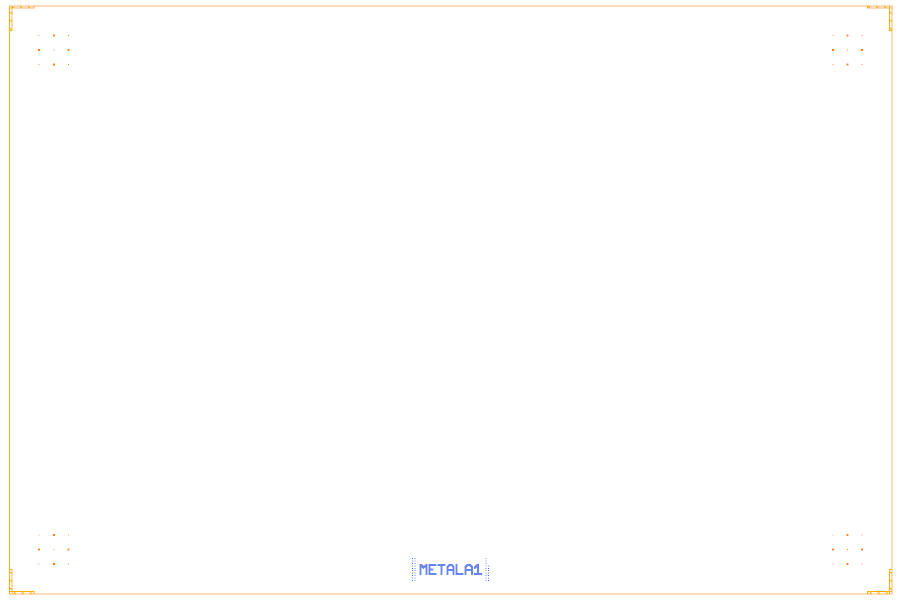

WindowsPath('examples/designs/metal/a1_transmon_readout_step_die.png')

In [4]:
d = Designer("a1_transmon_readout", box=(0, 0, 9000, 6000), chip={"name_chip": "MetalA1"}, live=LIVE)
X0, Y0 = 4500, 3000                              # Metal's 9 × 6 mm chip is centred on (0, 0)
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "a1_transmon_readout_step_die.png", size=(900, 600), width=450)

## 4 · Pads: the PDK pad rule

The tutorial puts its two `LaunchpadWirebond`s at x = ±4 mm on the feedline height. In the Quantcore PDK the outer
edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the die edge**, whatever the source did:
`edge="w"` / `"e"` (or `"auto"`, the nearest edge) slides the pad perpendicular to that edge until it is there; its
position along the edge (the feedline height) is kept. The table measures it on the built layout.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP1 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP2 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

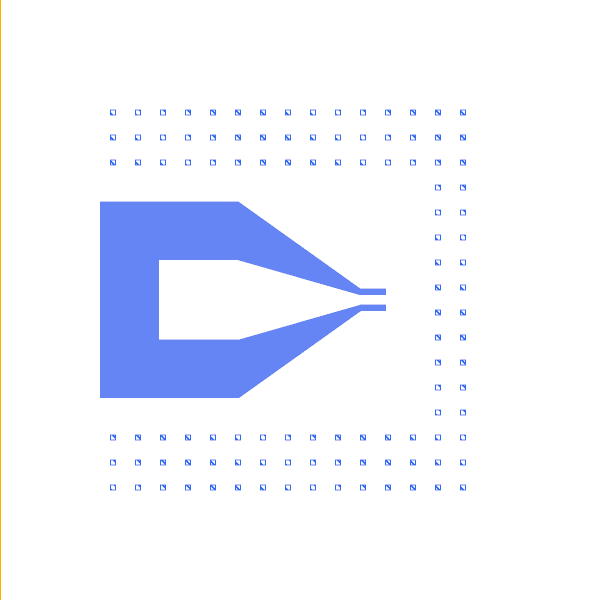

WindowsPath('examples/designs/metal/a1_transmon_readout_step_pads.png')

In [5]:
with d.batch():
    lp1 = d.add("LP1", "metal:LaunchpadWirebond", at=(X0 - 4000, Y0 + 1500), rot=0, edge="w")
    lp2 = d.add("LP2", "metal:LaunchpadWirebond", at=(X0 + 4000, Y0 + 1500), rot=180, edge="e")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "LP1.tie")
snap(d, OUT / "a1_transmon_readout_step_pads.png", box=(0, py - 300, 600, py + 300), size=(600, 600), width=300)

## 5 · Components: the qubit and the tee

**The qubit.** `metal:TransmonPocket` is Metal's pocket transmon drawn by the wrapper with the tutorial's options:
two 425 µm pads in a 650 µm-high pocket and one connection pad `readout`. Its junction is the PDK's: with
`junction_type` unset the wrapper already draws the Quantcore trilayer junction; `trilayer_junction` makes it
explicit and returns the drawn junction's L_J and C_J, which the LOM and the FEM junction port use (`junction=`).
The tutorial gives no target frequency, so Q1 gets the PDK nominal junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a
50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF).

**The tee.** `metal:CoupledLineTee` is a feedline section with a 350 µm coupled arm; `open_termination=False` shorts
the arm's far end, so the resonator routed from `second_end` is a λ/4 shorted at the tee.

Each component has named **ports** (Metal's pins): routes connect to them, and the LOM maps each to a circuit node.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['readout', 'squid_a', 'squid_b'] | clt ports: ['prime_end', 'prime_start', 'second_end']


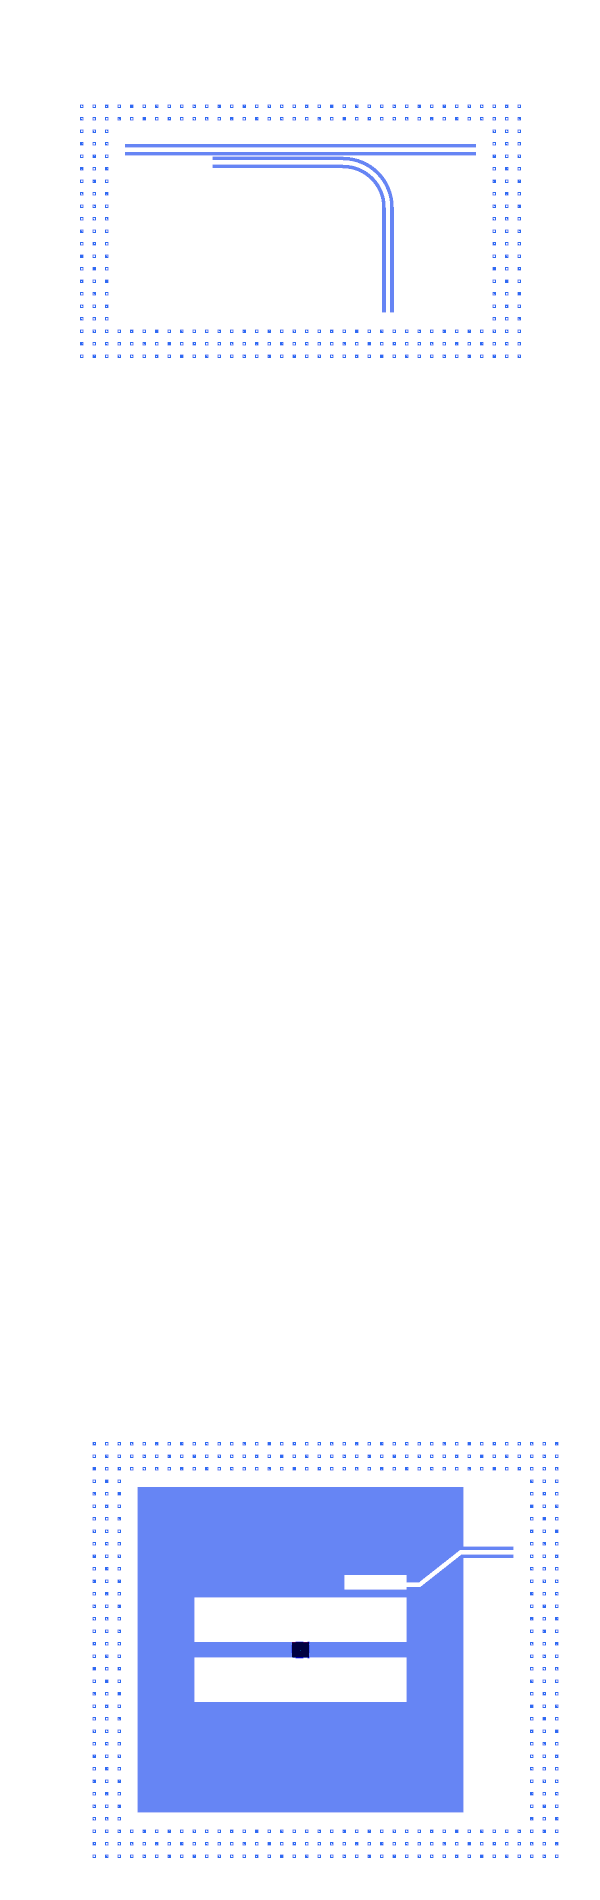

WindowsPath('examples/designs/metal/a1_transmon_readout_step_parts.png')

In [6]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    q1 = d.add("Q1", "metal:TransmonPocket", at=(X0 + 0, Y0 - 1500), pad_width=425, pocket_height=650,
               connection_pads={"readout": {"loc_W": 1, "loc_H": 1}}, junction=JUNCTION, **JJ_PARAMS)
    clt = d.add("clt", "metal:CoupledLineTee", at=(X0 + 0, Y0 + 1500), coupling_length=350, down_length=300,
                fillet=90, open_termination=False)
print("Q1 ports:", sorted(q1.ports), "| clt ports:", sorted(clt.ports))
snap(d, OUT / "a1_transmon_readout_step_parts.png", box=(X0 - 600, Y0 - 2000, X0 + 600, Y0 + 1800), size=(600, 1900),
     width=240)

## 6 · Routes: feedline and readout resonator

- **Feedline:** two `cpw` routes, launchpad → tee → launchpad, on the PDK's default CPW (10 µm centre, 6 µm gap)
  with the tutorial's 90 µm fillet as the turn radius.
- **Readout resonator:** `meander=7000` makes a fixed-length meander from the tee's coupled arm to the qubit's
  readout pad; the length sets the frequency (λ/4 on sapphire: f ≈ v_ph / 4ℓ).
- **Sim group:** `sim_group` names the part of the chip a FEM job cuts out (the qubit, its readout and the tee) and
  the analyses it gets.

route lengths (µm): {'feed_L': 3765.0, 'feed_R': 3765.0, 'readout_res': 7000.0}


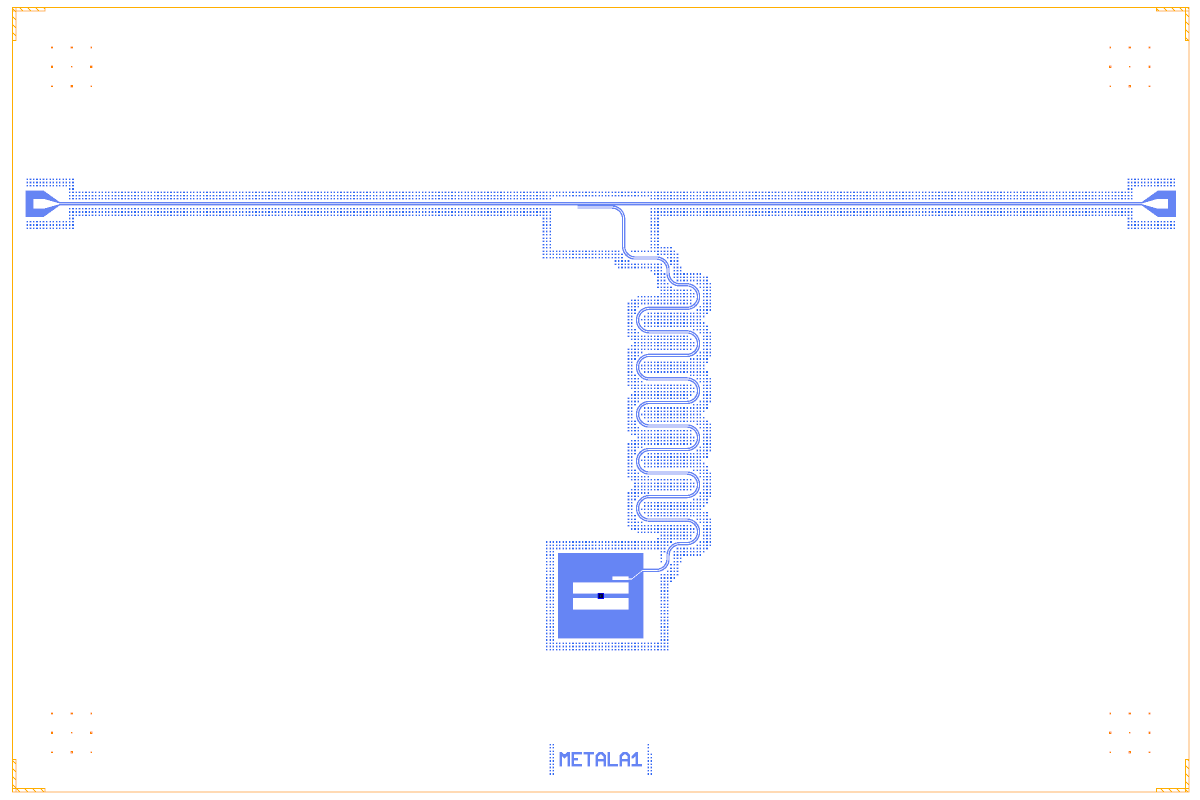

WindowsPath('examples/designs/metal/a1_transmon_readout_step_routes.png')

In [7]:
with d.batch():
    d.route("feed_L", lp1.tie, clt.prime_start, r=90)
    d.route("feed_R", clt.prime_end, lp2.tie, r=90)
    d.route("readout_res", clt.second_end, q1.readout, meander=7000, r=90)
d.sim_group("Q1_readout", ["Q1", "readout_res", "clt"], analyses=["q3d_cmatrix", "eigenmode_epr"])
rebuild(d)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "a1_transmon_readout_step_routes.png", size=(1200, 800), width=480)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). Here the pads already span the die in x, so only y moves (the source's qubit hangs
below its feedline). Then the design is saved: the JSON is the deliverable.

In [8]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN = d.save(OUT / "a1_transmon_readout.json")
print(d, "→", DESIGN, "| readout", round(d.result.route_lengths()["readout_res"], 1), "µm")

content shifted by (0.0, 113.5) µm
<Designer a1_transmon_readout: 4 instances, 3 routes, live=False> → examples\designs\metal\a1_transmon_readout.json | readout 7000.0 µm


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**, two `dangling_port` warnings (`Q1.squid_a` / `squid_b`, the junction's
attachment points: the qubit cell draws the junction itself, nothing is routed there) and **no PDK design
warnings** (the pads are at 100 µm, the nominal junction is in the R_n window, no target is outside 4–8 GHz).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 2 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 2 | Q1.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 1 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model gives its nodes and branches (the
pocket transmon: an island with its junction and C_Σ, a node for the readout pad; the tee: a coupling capacitor and
a hanger κ), and each route joins the nodes of the ports at its ends (the readout route becomes a λ/4 `TLres`, the
feedline halves join the launchpad ports, 50 Ω each). The port map shows which node each port landed on.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "clt."))})

**5 nodes · 11 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `clt.prime` | `LP1.pad`, `LP2.pad`, `clt.prime` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.readout` | `Q1.readout`, `clt.second_end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_LP1` | R | `clt.prime` – `gnd` | 50 Ω |
| `Port_LP2` | R | `clt.prime` – `gnd` | 50 Ω |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 34.3 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 34.3 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 26.2 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_readout` | C | `Q1.island1` – `Q1.readout` | 17 fF |
| `Cf_Q1_readout` | C | `Q1.island2` – `Q1.readout` | 1.8 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 34.3 fF |
| `clt` | TLres | `Q1.readout` – `gnd` | lambda/4, 7650 µm, 4.119 GHz |
| `K_clt` | HANGER | `Q1.readout` – `clt.prime` | κ 0.108 MHz (L 350 µm) |

**Unconnected ports:** none

**Builder notes:**

- clt: coupled-line κ uses the hanger k for a 3 µm gap (rough)

{'Q1.squid_a': 'Q1.island2', 'Q1.squid_b': 'Q1.island1', 'Q1.readout': 'Q1.readout', 'clt.prime_start': 'clt.prime', 'clt.prime_end': 'clt.prime', 'clt.second_end': 'Q1.readout'}


## 10 · LOM simulation

QuCat solves the circuit's normal modes (frequency, κ through the 50 Ω ports, anharmonicity); QuTiP diagonalises the
dressed Hamiltonian for f_q, α, f_r and χ. With the PDK junction (6.73 nH, 15 fF) the qubit sits near 7.4 GHz, above
the ≈ 4 GHz λ/4 readout as in the tutorial; the tutorial states no targets, so there is nothing to compare with
except the PDK band (4–8 GHz).

In [11]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| clt | resonator | 3.9306 | 0.0898 | 0.0 | clt 1.00 |
| Q1 | qubit | 7.7695 | 0.000599 | 310.6 | J_Q1 1.00 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `clt.f_GHz` | 3.9305 | – |
| `clt.kappa_MHz` | 0.089767 | – |
| `clt.chi_MHz` | -0.2054 | – |
| `Q1.f_q_GHz` | 7.4449 | – |
| `Q1.alpha_MHz` | -344.99 | – |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Two jobs for the group `Q1_readout`: a **Q3D C-matrix** (the capacitances of the island pads, the readout
pad and the tee arm: they replace the LOM estimates) and an **eigenmode / EPR** job (the lines leaving the box end in
50 Ω, so the mode Q gives κ, and EPR gives the junction participation).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN, ["Q1_readout"])
jobs_eig = export_sims(DESIGN, ["Q1_readout"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1_readout | `build/jobs/a1_transmon_readout_Q1_readout_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `clt.second_end`<br>3 · waveguide · `Q1.readout`<br>4 · edge · `feed_L`<br>5 · edge · `feed_R` | `Q1.island2`, `Q1.readout`, `feed_L`, `Q1.island1` |
| Q1_readout | `build/jobs/a1_transmon_readout_Q1_readout_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `feed_L`<br>3 · edge_lumped · `feed_R` | `Q1.island2`, `feed_L`, `feed_R`, `Q1.island1` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['Q1_readout'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()}, **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for Q1_readout · q3d, Q1_readout · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here the readout meander, 7000 → 6500 µm — rebuild, re-run the LOM and compare. A
shorter λ/4 resonates higher (f ∝ 1/ℓ, about +7 %); χ follows the smaller qubit–resonator detuning.

In [15]:
d2 = design_copy(DESIGN)
d2["readout_res"].set(length=6500)               # 7000 → 6500 µm
res2 = simulate_lom(d2.lom(), d2.design)
display(Markdown(params_delta_md(res, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `clt.f_GHz` | 3.9305 | 4.1921 | +0.2616 |
| `clt.kappa_MHz` | 0.089767 | 0.10853 | +0.01876 |
| `clt.chi_MHz` | -0.2054 | -0.29796 | -0.09256 |
| `Q1.f_q_GHz` | 7.4449 | 7.4454 | +0.0005929 |
| `Q1.alpha_MHz` | -344.99 | -344.91 | +0.07727 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The A.1 tutorial never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\a1_transmon_readout.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 3434 |
| 2/0 | JJ_STRAIGHT | 1 |
| 3/0 | M3 | 3427 |
| 4/0 | JJ_BENT | 1 |
| 50/0 | HSQ | 2 |
| 51/0 | SPACER_1 | 2 |
| 52/0 | SPACER_2 | 2 |
| 53/0 | SPACER_3 | 2 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 3425 holes on the mask.

→ `build/a1_transmon_readout_fab.oas`

## 15 · Snapshots

The full chip; the qubit pocket; its trilayer junction; the readout pad where the meander lands; the coupled-line
tee; the **fab mask** round the qubit (1/0 etch with the PDK cheese band, the 3/0 keep-out, the junction layers);
and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are read from the
design (after the centring shift).

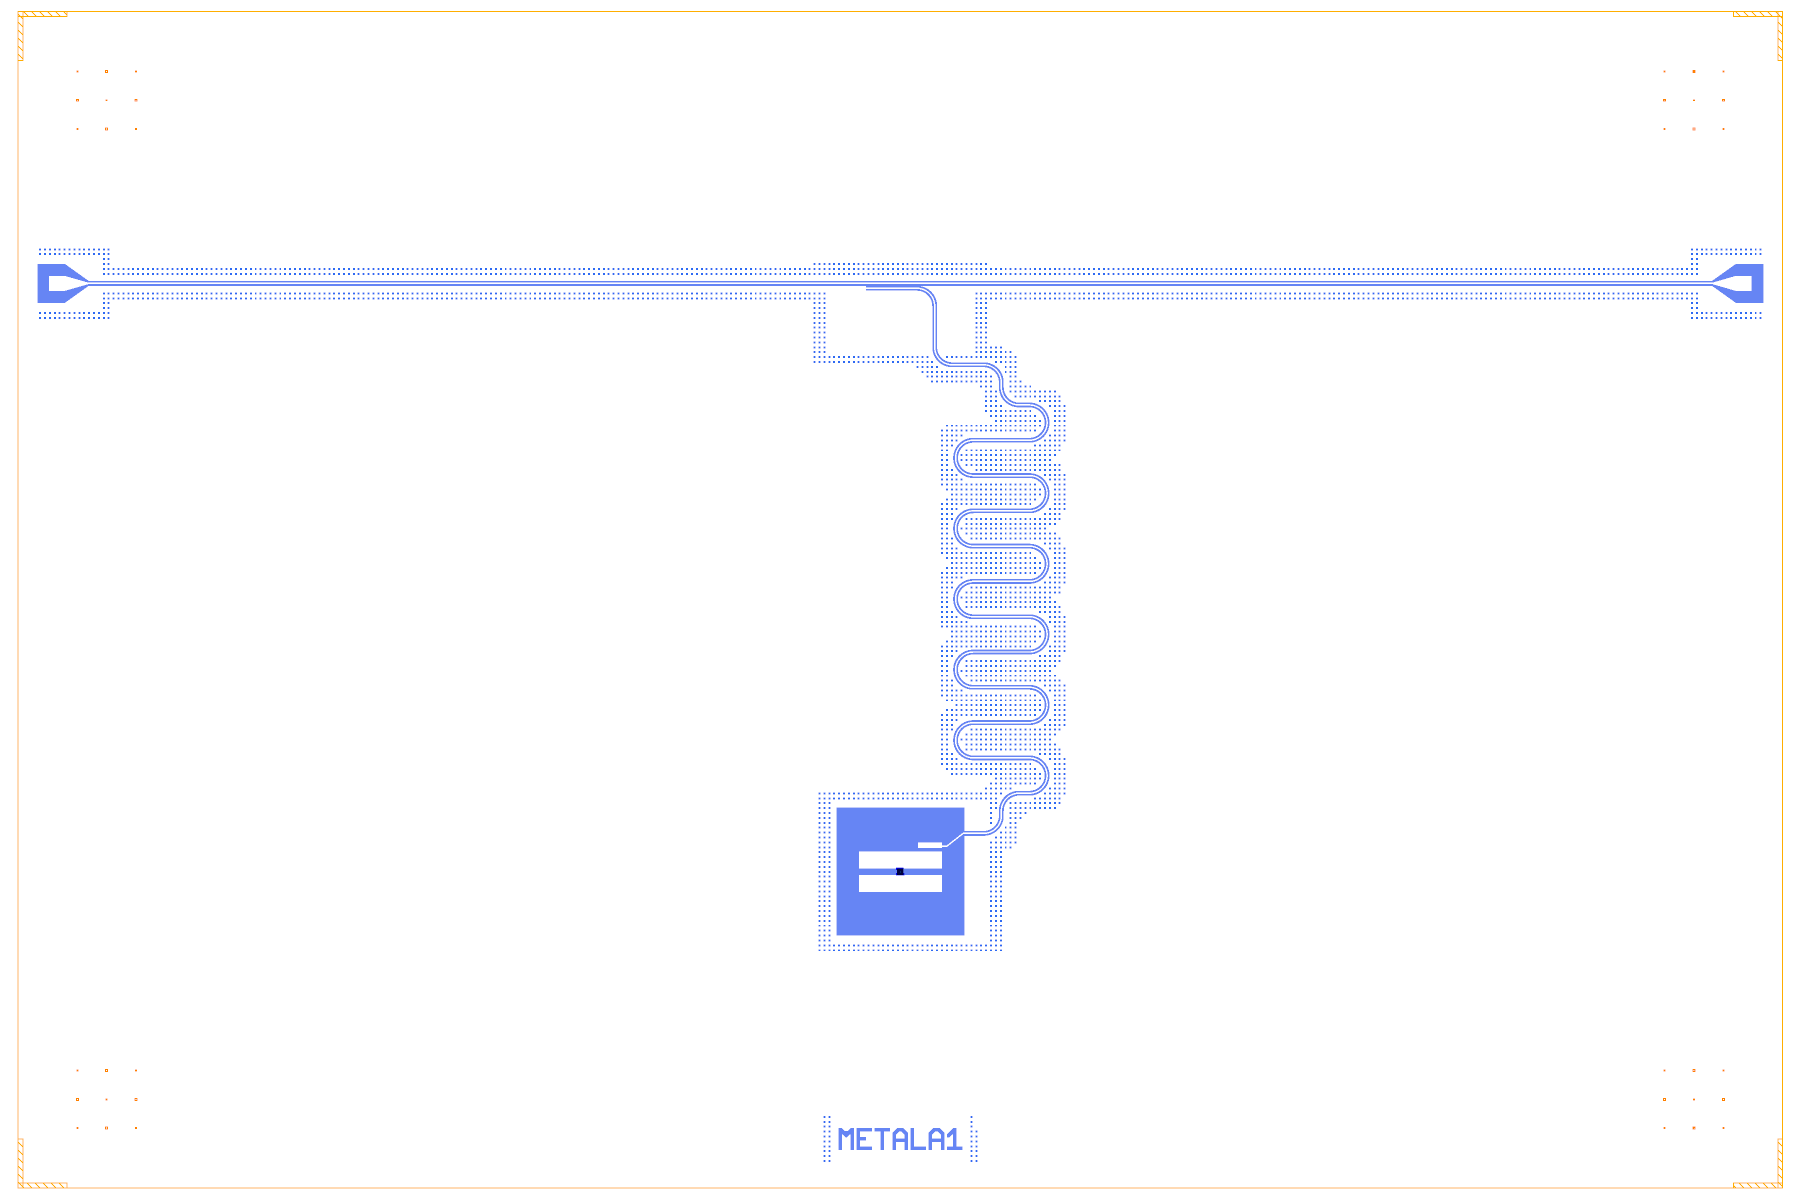

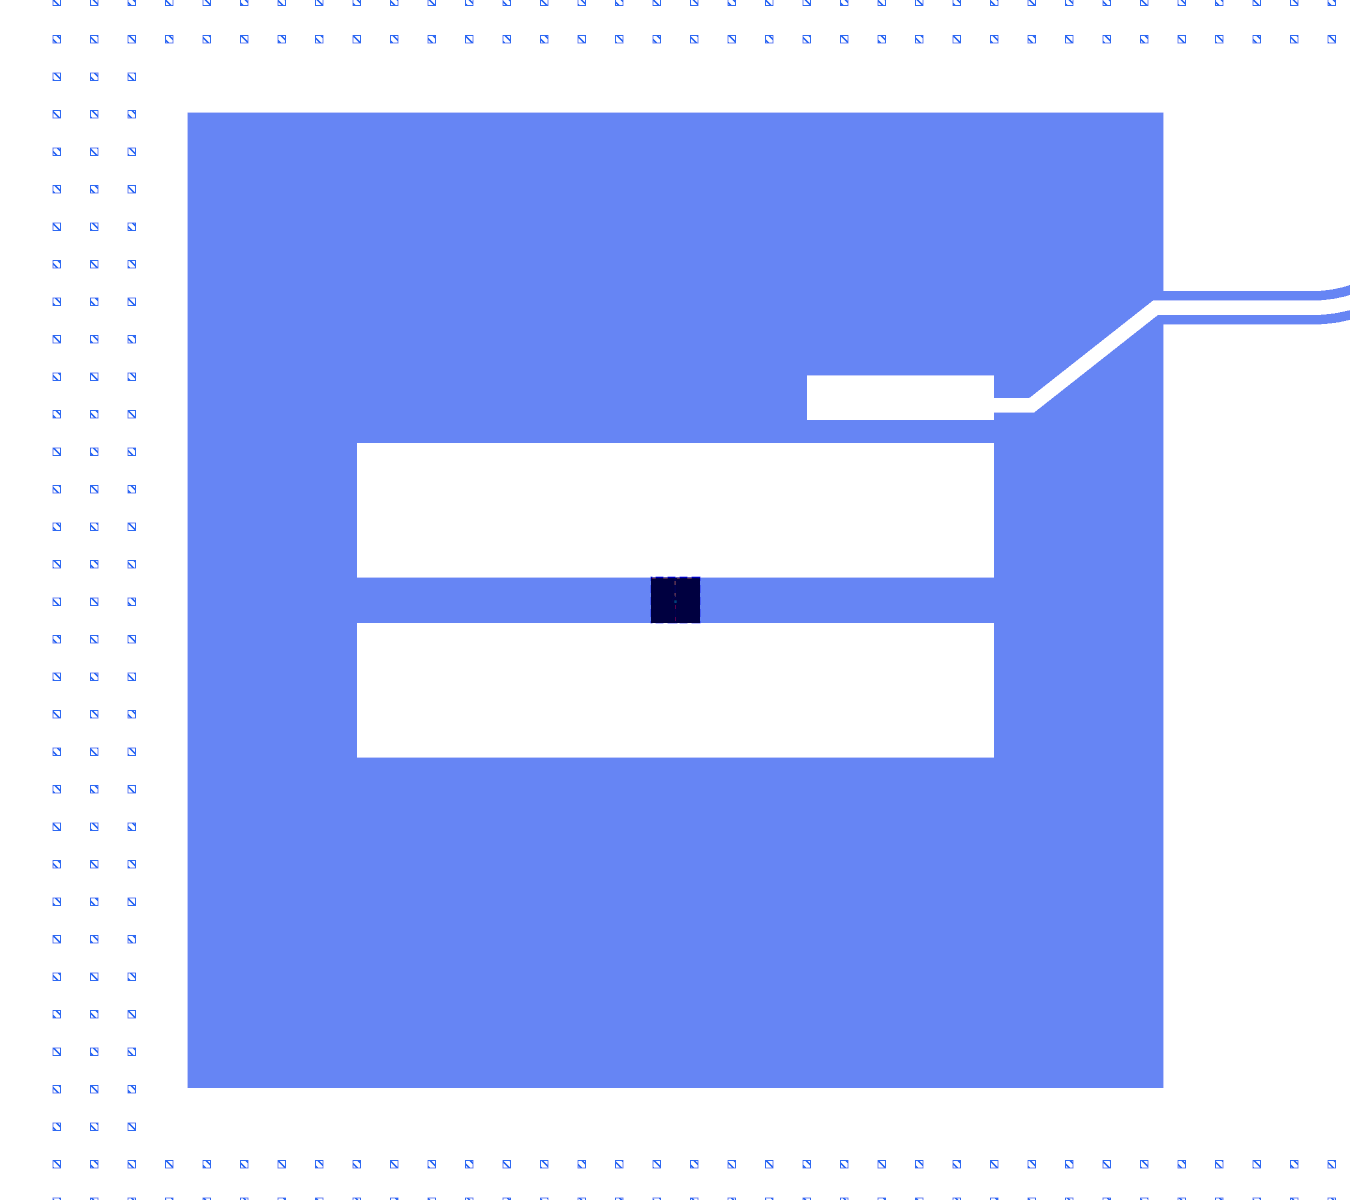

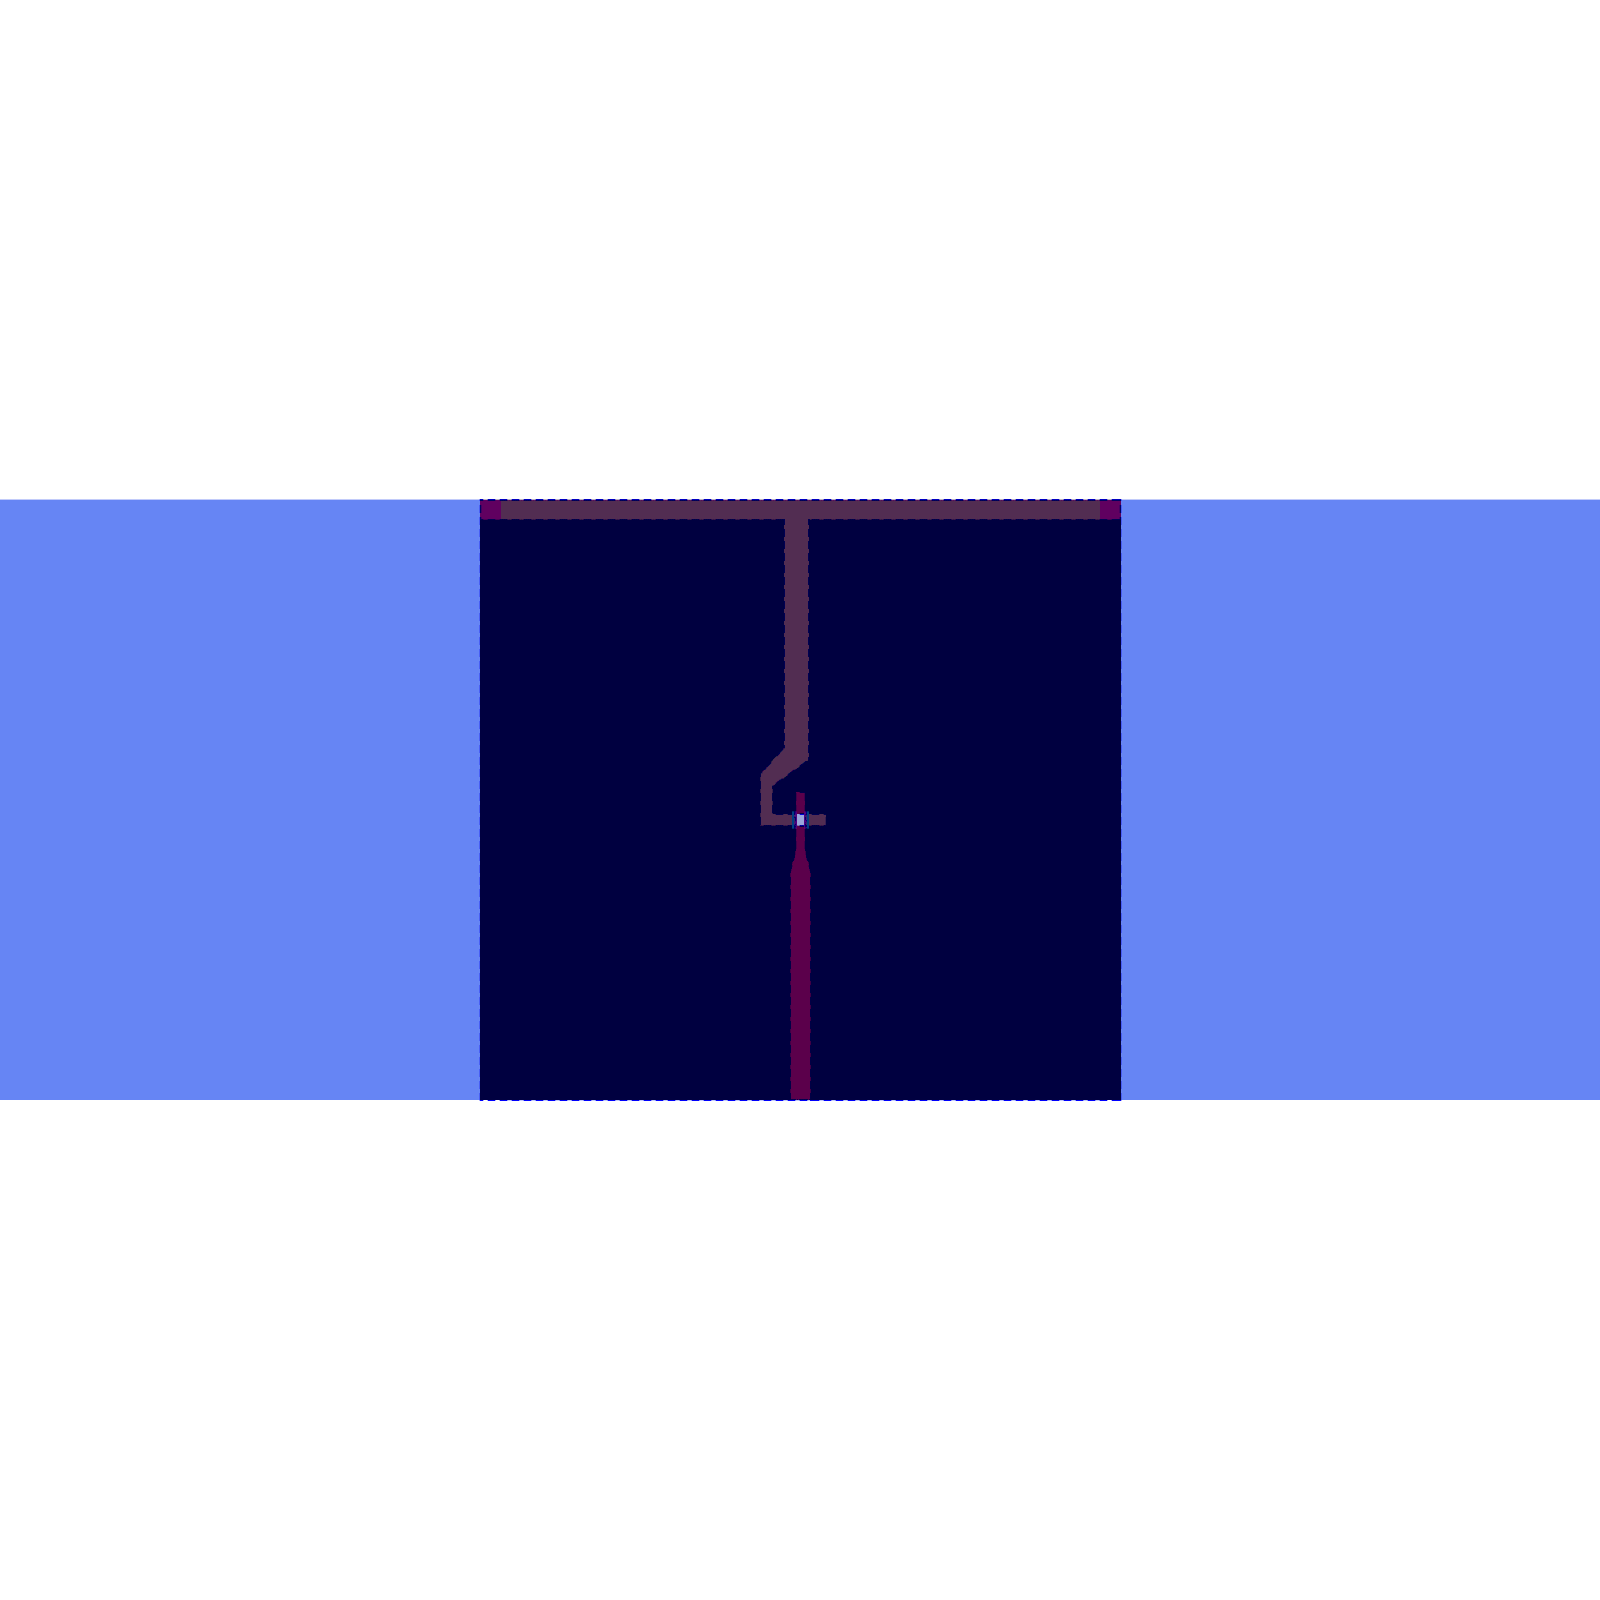

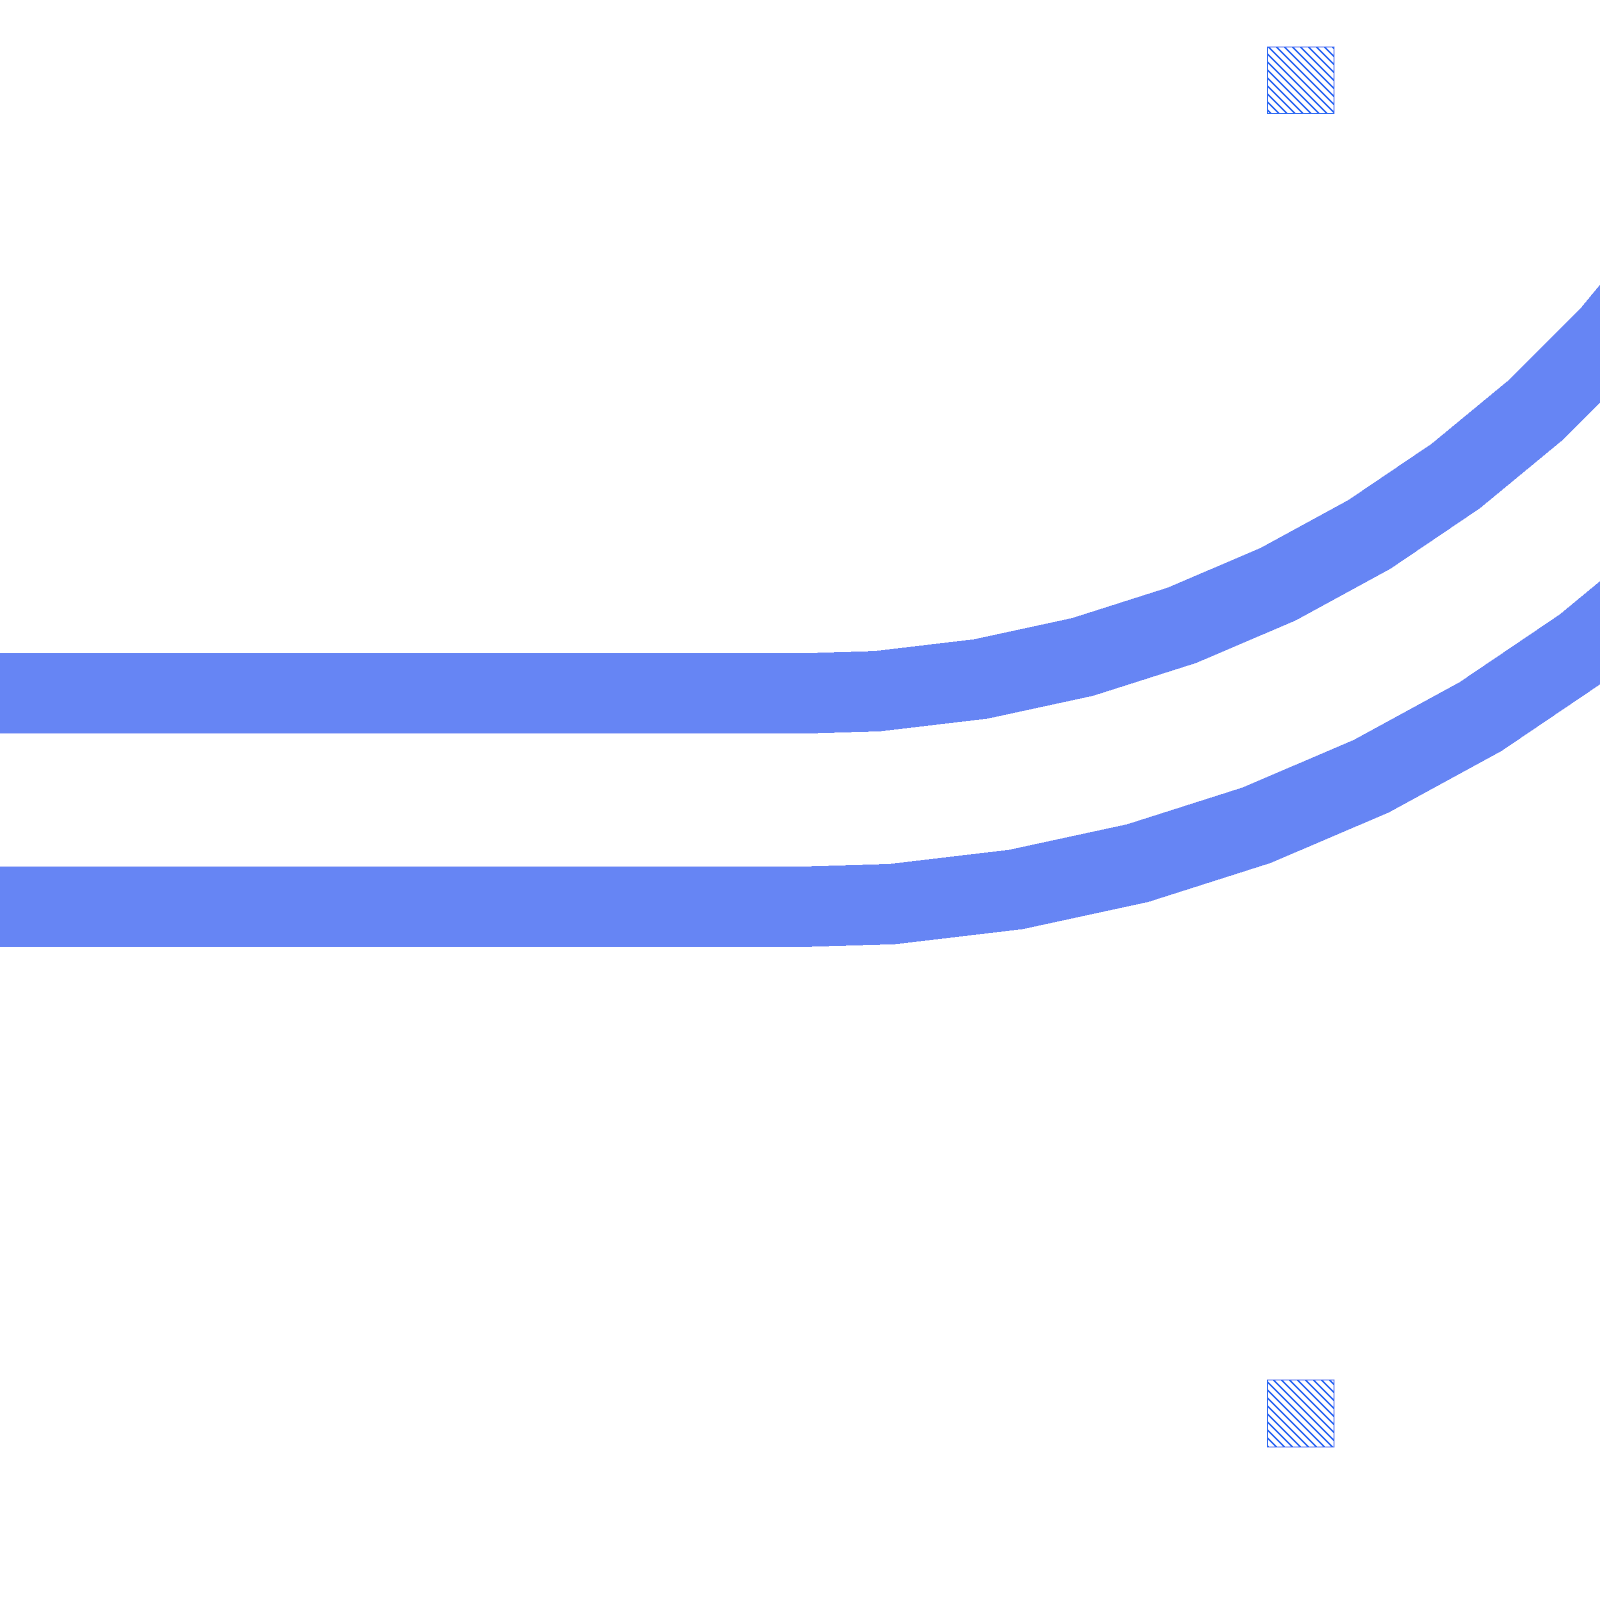

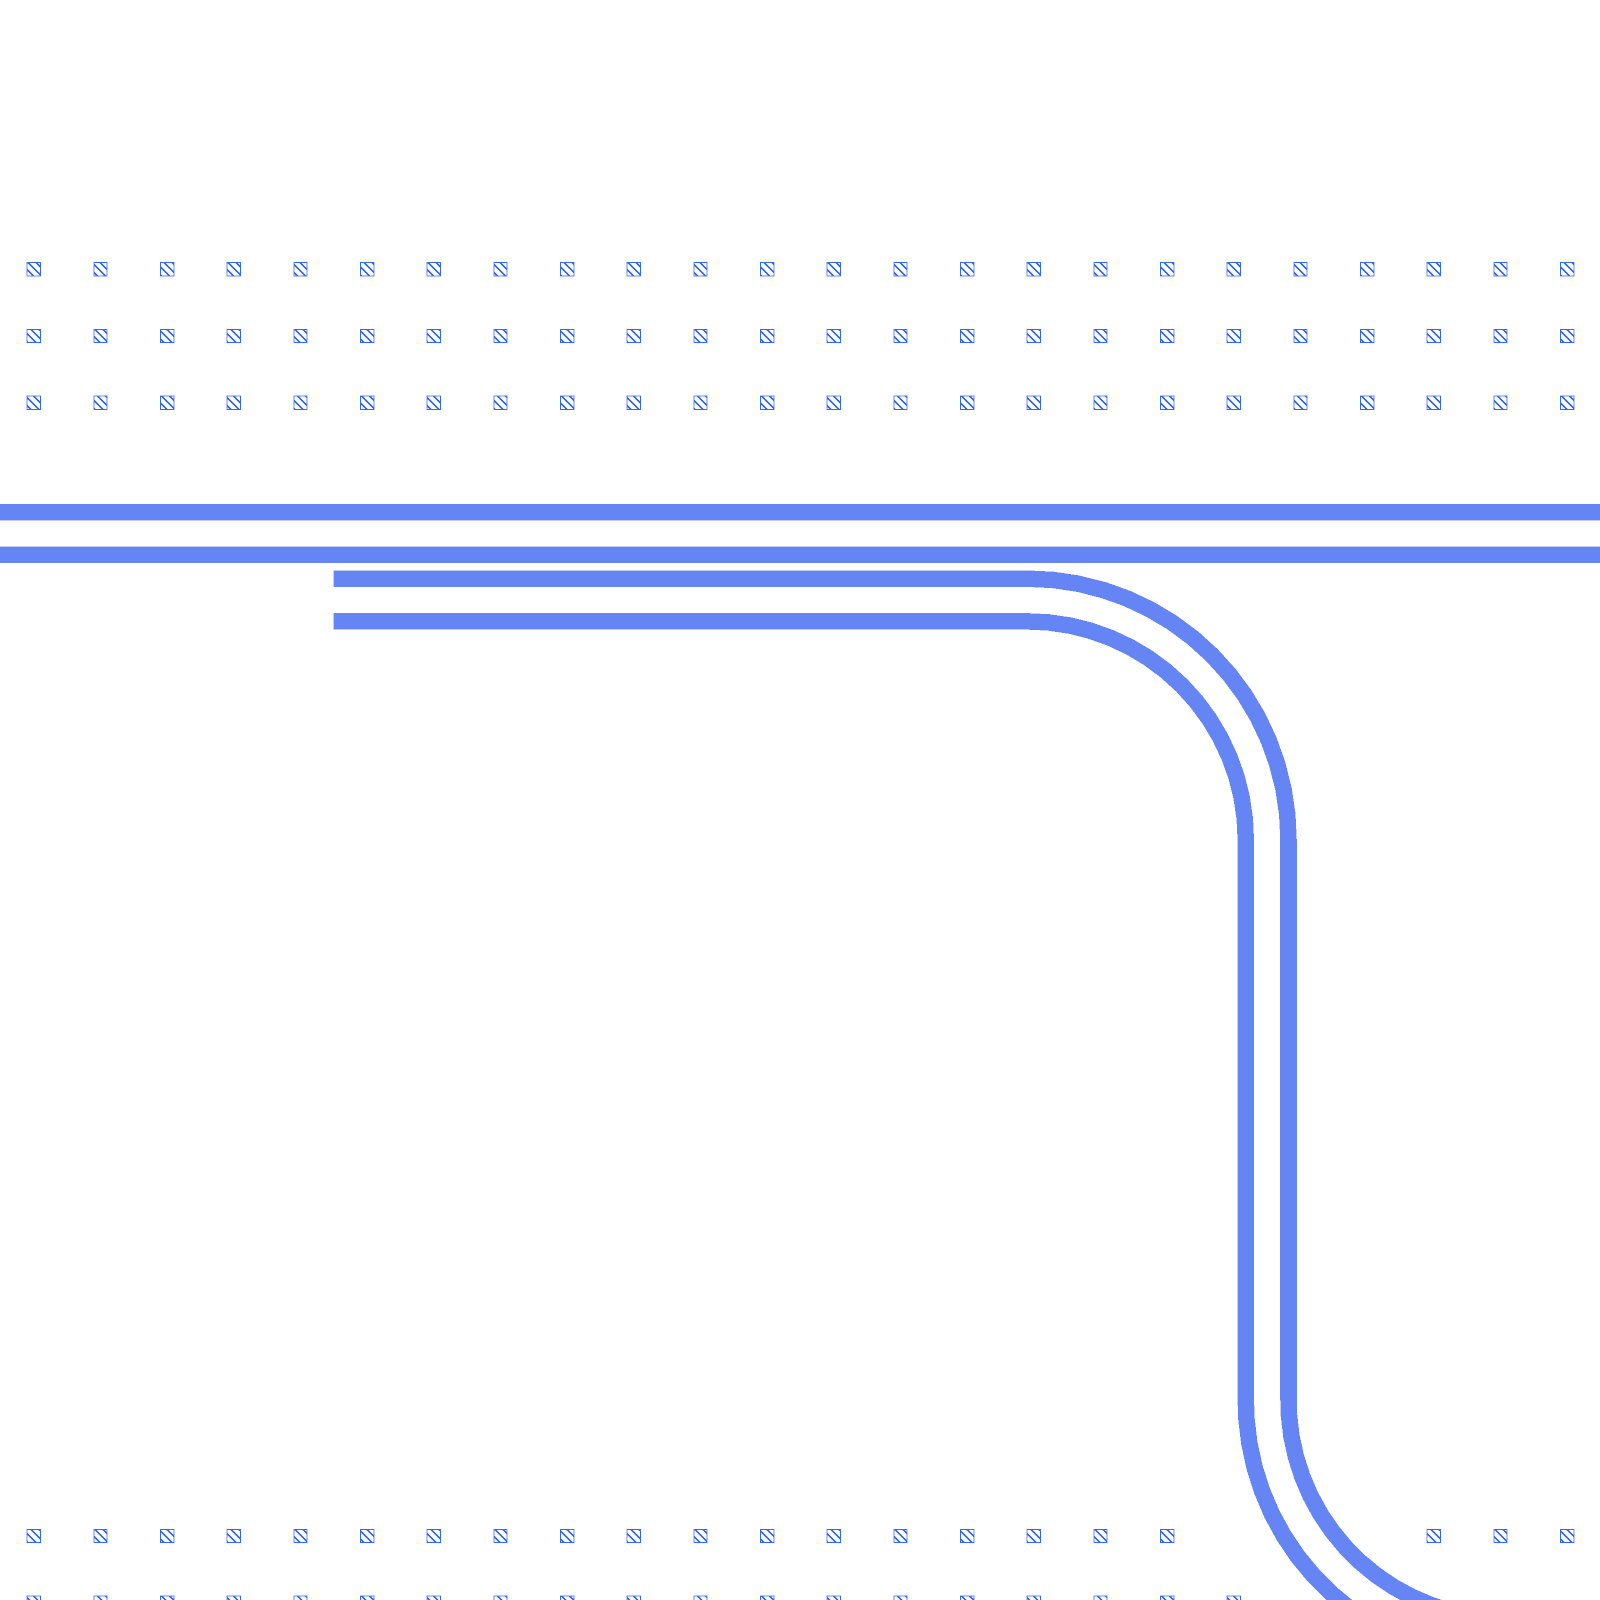

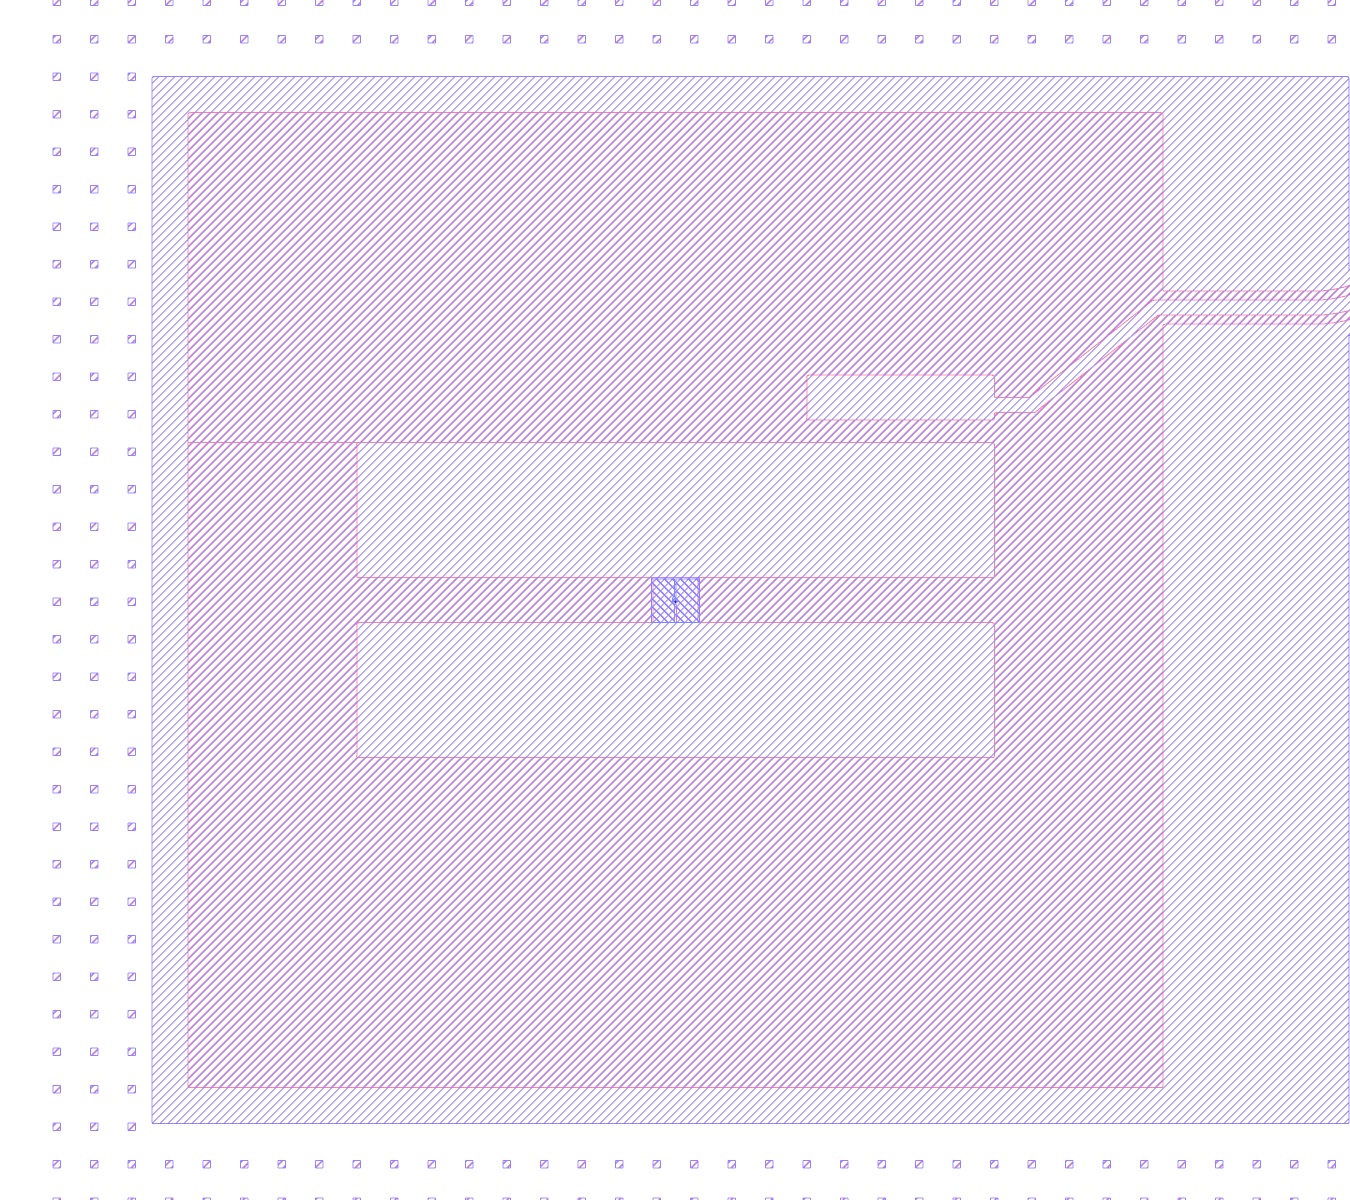

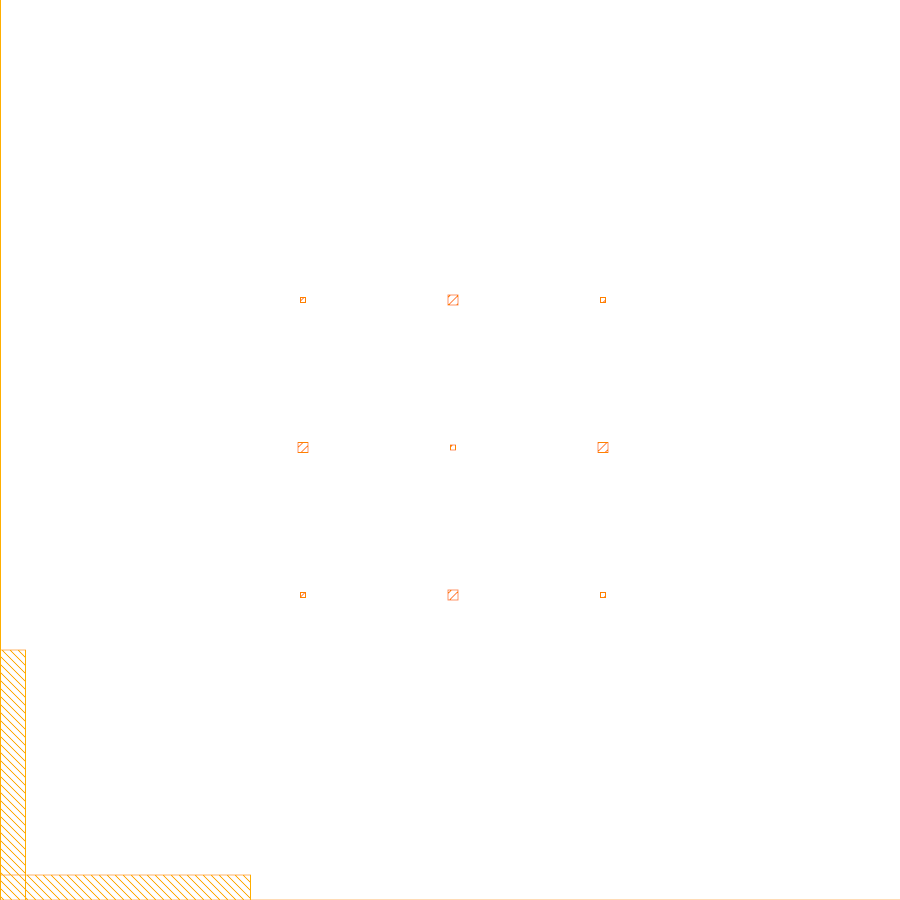

In [17]:
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
TX, TY = d.data["instances"]["clt"]["place"]["at"]
show_snapshot(d, OUT / "a1_transmon_readout.png", size=(1800, 1200))
show_snapshot(d, OUT / "a1_transmon_readout_q1.png", box=(QX - 450, QY - 400, QX + 450, QY + 400), size=(1350, 1200),
              width=420)
show_snapshot(d, OUT / "a1_transmon_readout_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
rx, ry = port_xy(d, "Q1.readout")
show_snapshot(d, OUT / "a1_transmon_readout_pin.png", box=(rx - 60, ry - 60, rx + 60, ry + 60), width=300)
show_snapshot(d, OUT / "a1_transmon_readout_tee.png", box=(TX - 300, TY - 400, TX + 300, TY + 200), width=360)
snap_file(Path("build") / "a1_transmon_readout_fab.oas", OUT / "a1_transmon_readout_cheese.png",
          box=(QX - 450, QY - 400, QX + 450, QY + 400), size=(1350, 1200), width=420)
show_snapshot(d, OUT / "a1_transmon_readout_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the route end pins, the 7 mm readout, the sim group |
| PDK changes | QCT frame on the source's 9 × 6 mm box; sapphire stack; launchpads 100 µm from the west / east edges (were 240 µm); trilayer junction (PDK nominal); PDK cheese band; content centred (shift printed in step 7) |
| differs | the readout meander's shape (qcc router); f_q ≈ 7.4 GHz with the PDK junction (the 10 nH Metal default gave 6.75 GHz) |
| PDK design warnings | none |
| open | the FEM jobs are exported, not solved (`RUN_FEM = False`) |